In [6]:
import pandas as pd
import numpy as np

# Change this path to your actual CSV
file_path = r"C:\Users\akifn\Documents\MachineLearningICPBL\data\raw\fail\episode_000001.csv"

df = pd.read_csv(file_path)

print("CSV successfully loaded!")

CSV successfully loaded!


In [7]:
# First 5 rows
display(df.head())

# Number of rows and columns
print("Shape:", df.shape)

# Column names
print("Columns:")
print(df.columns.tolist())

# Data types
df.info()

,episode_index,frame_index,index,task_index,timestamp,state.l_sh_p,state.l_sh_r,state.l_sh_y,state.l_el_p,state.l_wr_y,...,action.r_el_p,action.r_wr_y,action.r_wr_p,action.r_wr_r,action.r_hand_index,action.r_hand_middle,action.r_hand_pinky,action.r_hand_ring,action.r_hand_thumb_y,action.r_hand_thumb_p
0,1,0,0,0,0.000000,-0.221229,0.283451,-0.249464,-1.260405,0.554877,...,-1.225967,-0.876732,-0.451173,-0.109780,9.587380e-08,0.0,0.0,0.0,0.816170,0.0
1,1,1,1,0,0.033333,-0.221229,0.284026,-0.251765,-1.262370,0.560174,...,-1.222169,-0.879913,-0.456689,-0.113315,9.587380e-08,0.0,0.0,0.0,0.817174,0.0
2,1,2,2,0,0.066667,-0.221229,0.286087,-0.253970,-1.263425,0.564464,...,-1.219154,-0.880911,-0.458568,-0.114492,9.587380e-08,0.0,0.0,0.0,0.820332,0.0
3,1,3,3,0,0.100000,-0.221229,0.287142,-0.255791,-1.264240,0.567916,...,-1.212904,-0.888355,-0.464169,-0.115604,9.587380e-08,0.0,0.0,0.0,0.821452,0.0
4,1,4,4,0,0.133333,-0.221229,0.288580,-0.257181,-1.264767,0.570864,...,-1.207636,-0.890593,-0.465042,-0.116797,9.587380e-08,0.0,0.0,0.0,0.819614,0.0


Shape: (429, 57)
Columns:
['episode_index', 'frame_index', 'index', 'task_index', 'timestamp', 'state.l_sh_p', 'state.l_sh_r', 'state.l_sh_y', 'state.l_el_p', 'state.l_wr_y', 'state.l_wr_p', 'state.l_wr_r', 'state.l_hand_index', 'state.l_hand_middle', 'state.l_hand_pinky', 'state.l_hand_ring', 'state.l_hand_thumb_y', 'state.l_hand_thumb_p', 'state.r_sh_p', 'state.r_sh_r', 'state.r_sh_y', 'state.r_el_p', 'state.r_wr_y', 'state.r_wr_p', 'state.r_wr_r', 'state.r_hand_index', 'state.r_hand_middle', 'state.r_hand_pinky', 'state.r_hand_ring', 'state.r_hand_thumb_y', 'state.r_hand_thumb_p', 'action.l_sh_p', 'action.l_sh_r', 'action.l_sh_y', 'action.l_el_p', 'action.l_wr_y', 'action.l_wr_p', 'action.l_wr_r', 'action.l_hand_index', 'action.l_hand_middle', 'action.l_hand_pinky', 'action.l_hand_ring', 'action.l_hand_thumb_y', 'action.l_hand_thumb_p', 'action.r_sh_p', 'action.r_sh_r', 'action.r_sh_y', 'action.r_el_p', 'action.r_wr_y', 'action.r_wr_p', 'action.r_wr_r', 'action.r_hand_index', 'actio

In [8]:
missing = df.isnull().sum()

print("Total missing values:", missing.sum())

print("\nColumns with missing values:")
print(missing[missing > 0])

Total missing values: 0

Columns with missing values:
Series([], dtype: int64)


In [9]:
timestamp_diff = df["timestamp"].diff()

print("Timestamp differences:")
print(timestamp_diff.describe())

print("\nAll timestamps increasing:",
      df["timestamp"].is_monotonic_increasing)

Timestamp differences:
count    4.280000e+02
mean     3.333333e-02
std      6.662134e-16
min      3.333333e-02
25%      3.333333e-02
50%      3.333333e-02
75%      3.333333e-02
max      3.333333e-02
Name: timestamp, dtype: float64

All timestamps increasing: True


In [10]:
from pathlib import Path

DATA_DIR = Path(r"C:\Users\akifn\Documents\MachineLearningICPBL\data\raw")

csv_files = sorted(DATA_DIR.rglob("*.csv"))

print("Total CSV files:", len(csv_files))

print("Success:", len(list((DATA_DIR / "success").glob("*.csv"))))
print("Fail:", len(list((DATA_DIR / "fail").glob("*.csv"))))

Total CSV files: 48
Success: 27
Fail: 21


In [11]:
import sys
import os

sys.path.append(os.path.abspath(".."))
import importlib
import src.load

importlib.reload(src.load)

episodes, labels = src.load.load_folder(r"C:\Users\akifn\Documents\MachineLearningICPBL\data\raw")
report = src.load.check_episodes(episodes)

display(report)

,episode,n_frames,duration_s,n_missing,n_columns,same_schema,time_increasing,correct_30fps
0,000002,516,17.166667,0,57,True,True,True
1,000009,389,12.933333,0,57,True,True,True
2,000014,299,9.933333,0,57,True,True,True
3,000016,377,12.533333,0,57,True,True,True
4,000017,363,12.066667,0,57,True,True,True
5,000020,411,13.666667,0,57,True,True,True
6,000022,304,10.100000,0,57,True,True,True
7,000023,298,9.900000,0,57,True,True,True
8,000024,326,10.833333,0,57,True,True,True
9,000026,328,10.900000,0,57,True,True,True


In [12]:
import pandas as pd

label_df = pd.DataFrame({
    "episode": list(labels.keys()),
    "label": list(labels.values())
})

label_df["label_name"] = label_df["label"].map({
    1: "success",
    0: "fail"
})

print(label_df["label_name"].value_counts())

label_name
success    27
fail       21
Name: count, dtype: int64


In [13]:
from src.load import load_folder, check_episodes

episodes, labels = load_folder(r"C:\Users\akifn\Documents\MachineLearningICPBL\data\raw")

report = check_episodes(episodes)

display(report.head())

,episode,n_frames,duration_s,n_missing,n_columns,same_schema,time_increasing,correct_30fps
0,000002,516,17.166667,0,57,True,True,True
1,000009,389,12.933333,0,57,True,True,True
2,000014,299,9.933333,0,57,True,True,True
3,000016,377,12.533333,0,57,True,True,True
4,000017,363,12.066667,0,57,True,True,True


In [14]:
report["label"] = report["episode"].map(labels)

print(
    report.groupby("label")["duration_s"]
    .agg(["count", "mean", "median", "min", "max"])
)

       count       mean     median       min        max
label                                                  
0         21  11.779365  11.433333  8.833333  14.933333
1         27  10.823457  10.433333  8.900000  17.166667


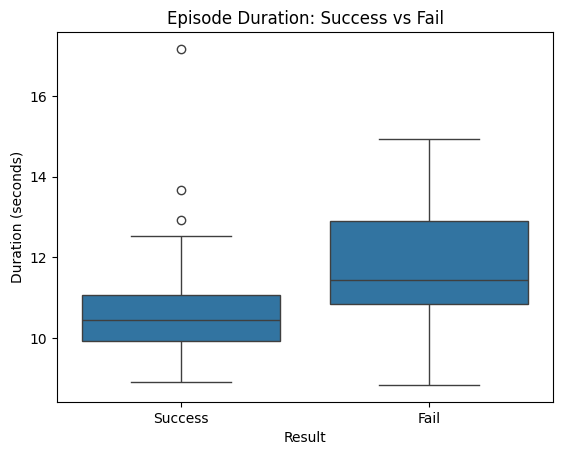

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

report["label_name"] = report["label"].map({
    1: "Success",
    0: "Fail"
})

sns.boxplot(
    data=report,
    x="label_name",
    y="duration_s"
)

plt.title("Episode Duration: Success vs Fail")
plt.xlabel("Result")
plt.ylabel("Duration (seconds)")
plt.show()

In [17]:
report.to_csv(r"C:\Users\akifn\Documents\MachineLearningICPBL\reports\episode_validation_report.csv", index=False)

In [18]:
report["label"] = report["episode"].map(labels)

duration_stats = (
    report.groupby("label")["duration_s"]
    .agg(["count", "mean", "median", "min", "max"])
)

display(duration_stats)

,count,mean,median,min,max
label,,,,,
0,21,11.779365,11.433333,8.833333,14.933333
1,27,10.823457,10.433333,8.900000,17.166667


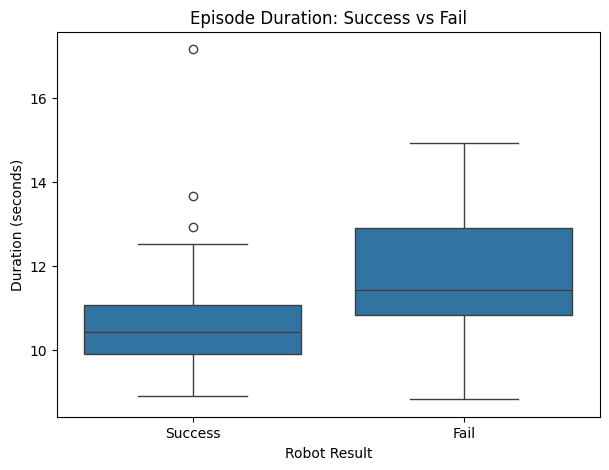

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

report["label_name"] = report["label"].map({
    1: "Success",
    0: "Fail"
})

plt.figure(figsize=(7, 5))

sns.boxplot(
    data=report,
    x="label_name",
    y="duration_s"
)

plt.title("Episode Duration: Success vs Fail")
plt.xlabel("Robot Result")
plt.ylabel("Duration (seconds)")

plt.show()

What are we calculating?
For each joint:
\[
Movement = |FinalPosition - InitialPosition|
\]

Then we calculate the average movement across the selected joints.
- l_arm_movement = average left-side joint displacement.
- r_arm_movement = average right-side joint displacement.

In [22]:
import numpy as np
import pandas as pd

movement_results = []

for eid, df in episodes.items():

    result = {"episode": eid}

    for side in ["l", "r"]:

        joint_columns = [
            col for col in df.columns
            if col.startswith(f"state.{side}_")
            and "hand" not in col
        ]

        movements = (
            df[joint_columns].iloc[-1]
            - df[joint_columns].iloc[0]
        ).abs()

        result[f"{side}_arm_movement"] = movements.mean()

    movement_results.append(result)

movement_df = pd.DataFrame(movement_results)

display(movement_df.head())

,episode,l_arm_movement,r_arm_movement
0,000002,0.051484,0.113367
1,000009,0.054148,0.071108
2,000014,0.063112,0.055442
3,000016,0.092919,0.034501
4,000017,0.088022,0.043825


In [24]:
movement_summary = movement_df[
    ["l_arm_movement", "r_arm_movement"]
].agg(["mean", "median", "min", "max"])

display(movement_summary)

,l_arm_movement,r_arm_movement
mean,0.067764,0.056649
median,0.060724,0.048863
min,0.028834,0.013128
max,0.126064,0.265207


In [25]:
movement_df["label"] = movement_df["episode"].map(labels)

display(
    movement_df.groupby("label")[
        ["l_arm_movement", "r_arm_movement"]
    ].mean()
)


,l_arm_movement,r_arm_movement
label,,
0,0.064967,0.059064
1,0.069939,0.054771


In [28]:
##net displacement
movements = (
    df[joint_columns].iloc[-1]
    - df[joint_columns].iloc[0]
).abs()

total joint movement:

In [29]:
total_movement_results = []

for eid, df in episodes.items():

    result = {"episode": eid}

    for side in ["l", "r"]:

        joint_columns = [
            col for col in df.columns
            if col.startswith(f"state.{side}_")
            and "hand" not in col
        ]

        # Calculate movement between consecutive frames
        frame_movement = df[joint_columns].diff().abs()

        # Total movement for each joint
        joint_total = frame_movement.sum()

        # Average total movement across joints
        result[f"{side}_total_movement"] = joint_total.mean()

    total_movement_results.append(result)

total_movement_df = pd.DataFrame(total_movement_results)

display(total_movement_df.head())

,episode,l_total_movement,r_total_movement
0,000002,1.725982,0.846001
1,000009,1.320011,0.842803
2,000014,1.166360,0.586563
3,000016,1.306222,0.793075
4,000017,1.312105,0.857191


In [30]:
df[joint_columns].diff().abs().sum()

state.r_sh_p    0.286423
state.r_sh_r    0.391165
state.r_sh_y    0.774852
state.r_el_p    0.978392
state.r_wr_y    0.552568
state.r_wr_p    0.459403
state.r_wr_r    0.636386
dtype: float64

In [31]:
display(
    total_movement_df[
        ["l_total_movement", "r_total_movement"]
    ].agg(["mean", "median", "min", "max"])
)

,l_total_movement,r_total_movement
mean,1.288577,0.650778
median,1.303711,0.629103
min,1.039532,0.480588
max,1.725982,1.039231


One question to think about: If the left arm moves more than the right arm, does that automatically mean the right arm is useless?

**HOLDOUT SPLIT GENERATION:**

In [32]:
from sklearn.model_selection import train_test_split

# Separate success and fail episode IDs
success_ids = [
    eid for eid, label in labels.items()
    if label == 1
]

fail_ids = [
    eid for eid, label in labels.items()
    if label == 0
]

# Randomly select 4 from each class
_, holdout_success = train_test_split(
    success_ids,
    test_size=4,
    random_state=42
)

_, holdout_fail = train_test_split(
    fail_ids,
    test_size=4,
    random_state=42
)

# Combine holdout IDs
holdout_ids = sorted(holdout_success + holdout_fail)

print("Holdout episodes:", holdout_ids)
print("Total holdout:", len(holdout_ids))

Holdout episodes: ['000001', '000003', '000024', '000025', '000026', '000031', '000035', '000040']
Total holdout: 8


In [33]:
from pathlib import Path
import shutil

RAW_DIR = Path("C:\\Users\\akifn\\Documents\\MachineLearningICPBL\\data\\raw")
HOLDOUT_DIR = Path("C:\\Users\\akifn\\Documents\\MachineLearningICPBL\\data\\holdout")

for eid in holdout_ids:

    label = labels[eid]

    label_name = "success" if label == 1 else "fail"

    source = RAW_DIR / label_name / f"episode_{eid}.csv"
    destination_folder = HOLDOUT_DIR / label_name

    destination_folder.mkdir(parents=True, exist_ok=True)

    shutil.copy2(
        source,
        destination_folder / source.name
    )

print("Holdout dataset created!")

Holdout dataset created!


In [34]:
holdout_episodes, holdout_labels = load_folder("C:\\Users\\akifn\\Documents\\MachineLearningICPBL\\data\\holdout")

print("Total:", len(holdout_episodes))
print("Success:", sum(v == 1 for v in holdout_labels.values()))
print("Fail:", sum(v == 0 for v in holdout_labels.values()))

Total: 8
Success: 4
Fail: 4


**Phase detection**
1. Reach

Robot moves its arm towards the object.

2. Grasp

Robot closes its fingers to grab the object.

3. Carry

Robot transports the object.

4. Release

Robot opens its fingers and releases the object.

5. Return

Robot moves its arm back to its initial position.

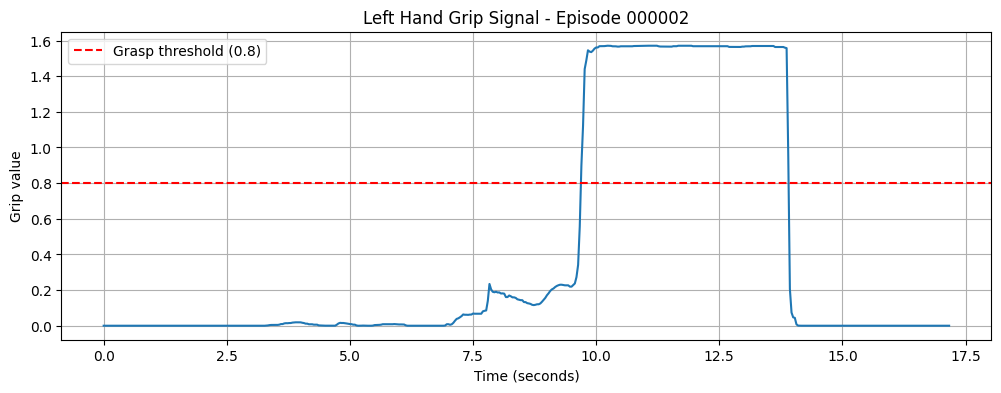

In [35]:
import matplotlib.pyplot as plt

# Choose one development episode (not holdout)
train_ids = [
    eid for eid in episodes
    if eid not in holdout_ids
]

sample_id = train_ids[0]
df = episodes[sample_id]

# Select the four left finger columns
finger_columns = [
    "state.l_hand_index",
    "state.l_hand_middle",
    "state.l_hand_ring",
    "state.l_hand_pinky"
]

# Calculate average grip
grip = df[finger_columns].mean(axis=1)

# Plot grip signal
plt.figure(figsize=(12, 4))

plt.plot(df["timestamp"], grip)

plt.axhline(
    y=0.8,
    color="red",
    linestyle="--",
    label="Grasp threshold (0.8)"
)

plt.title(f"Left Hand Grip Signal - Episode {sample_id}")
plt.xlabel("Time (seconds)")
plt.ylabel("Grip value")
plt.legend()
plt.grid()
plt.show()

In [36]:
##phases.py tests
from src.phases import detect_phases

phases = detect_phases(df)

print(phases)
print("Grasp time:", df["timestamp"].iloc[phases["grasp_idx"]])
print("Release time:", df["timestamp"].iloc[phases["release_idx"]])

{'grasp_idx': 291, 'release_idx': 417, 'open_idx': 418, 'n_grasps': 1, 'end_idx': 515, 'grasp_events': [{'grasp_idx': 291, 'release_idx': 417, 'open_idx': 418}]}
Grasp time: 9.7
Release time: 13.9


In [ ]:
##grasp on success episodes
from src.phases import detect_phases

for eid, df in list(episodes.items())[:10]:
    result = detect_phases(df)

    print(
        f"Episode {eid} | Label: {labels[eid]} | "
        f"Grasps: {result['n_grasps']} | "
        f"Grasp: {result['grasp_idx']} | "
        f"Release: {result['release_idx']}"
    )

Episode 000002 | Label: 1 | Grasps: 1 | Grasp: 291 | Release: 417
Episode 000009 | Label: 1 | Grasps: 1 | Grasp: 196 | Release: 307
Episode 000014 | Label: 1 | Grasps: 1 | Grasp: 133 | Release: 233
Episode 000016 | Label: 1 | Grasps: 1 | Grasp: 163 | Release: 307
Episode 000017 | Label: 1 | Grasps: 1 | Grasp: 135 | Release: 292
Episode 000020 | Label: 1 | Grasps: 1 | Grasp: 166 | Release: 325
Episode 000022 | Label: 1 | Grasps: 1 | Grasp: 102 | Release: 245
Episode 000023 | Label: 1 | Grasps: 1 | Grasp: 119 | Release: 204
Episode 000024 | Label: 1 | Grasps: 1 | Grasp: 148 | Release: 268
Episode 000026 | Label: 1 | Grasps: 1 | Grasp: 169 | Release: 261


In [38]:
##grasp on failed episodes
for eid, df in episodes.items():
    if labels[eid] == 0:
        result = detect_phases(df)

        print(
            f"Episode {eid} | "
            f"Grasps: {result['n_grasps']} | "
            f"Grasp: {result['grasp_idx']} | "
            f"Release: {result['release_idx']}"
        )

Episode 000001 | Grasps: 1 | Grasp: 162 | Release: 326
Episode 000003 | Grasps: 1 | Grasp: 199 | Release: 361
Episode 000004 | Grasps: 1 | Grasp: 124 | Release: 278
Episode 000005 | Grasps: 1 | Grasp: 159 | Release: 311
Episode 000006 | Grasps: 1 | Grasp: 99 | Release: 251
Episode 000007 | Grasps: 1 | Grasp: 139 | Release: 269
Episode 000008 | Grasps: 1 | Grasp: 219 | Release: 353
Episode 000010 | Grasps: 1 | Grasp: 200 | Release: 317
Episode 000011 | Grasps: 1 | Grasp: 192 | Release: 293
Episode 000012 | Grasps: 1 | Grasp: 165 | Release: 262
Episode 000013 | Grasps: 1 | Grasp: 191 | Release: 313
Episode 000015 | Grasps: 1 | Grasp: 115 | Release: 198
Episode 000018 | Grasps: 1 | Grasp: 155 | Release: 230
Episode 000019 | Grasps: 1 | Grasp: 131 | Release: 270
Episode 000021 | Grasps: 1 | Grasp: 167 | Release: 314
Episode 000025 | Grasps: 1 | Grasp: 167 | Release: 270
Episode 000028 | Grasps: 1 | Grasp: 139 | Release: 239
Episode 000035 | Grasps: 1 | Grasp: 155 | Release: 279
Episode 000

In [39]:
##compare grasp dddduration
grasp_results = []

for eid, df in episodes.items():
    result = detect_phases(df)

    duration = (
        result["release_idx"] - result["grasp_idx"]
    ) / 30

    grasp_results.append({
        "episode": eid,
        "label": labels[eid],
        "grasp_duration": duration
    })

grasp_df = pd.DataFrame(grasp_results)

display(
    grasp_df.groupby("label")["grasp_duration"]
    .agg(["count", "mean", "median", "min", "max"])
)

,count,mean,median,min,max
label,,,,,
0,21,4.179365,4.133333,2.500000,5.466667
1,27,3.901235,3.933333,2.833333,5.300000


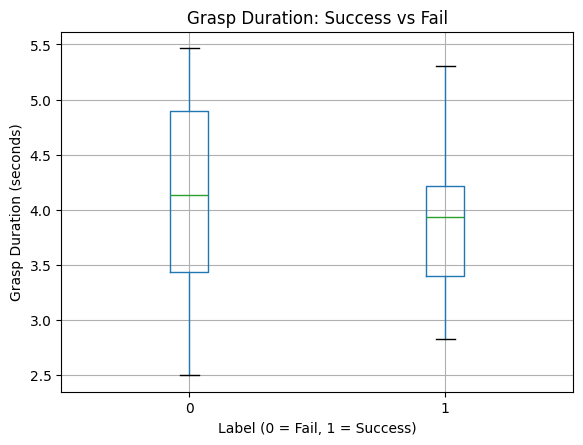

In [40]:
import matplotlib.pyplot as plt

grasp_df.boxplot(
    column="grasp_duration",
    by="label"
)

plt.title("Grasp Duration: Success vs Fail")
plt.suptitle("")
plt.xlabel("Label (0 = Fail, 1 = Success)")
plt.ylabel("Grasp Duration (seconds)")
plt.show()

In [ ]:
##arm movement after release
return_results = []

for eid, df in episodes.items():
    result = detect_phases(df)
    release_idx = result["release_idx"]

    joint_columns = [
        col for col in df.columns
        if col.startswith("state.l_")
        and "hand" not in col
    ]

    initial = df[joint_columns].iloc[0]
    final = df[joint_columns].iloc[-1]

    final_error = (final - initial).abs().mean()

    return_results.append({
        "episode": eid,
        "label": labels[eid],
        "final_position_error": final_error
    })

return_df = pd.DataFrame(return_results)

display(
    return_df.groupby("label")["final_position_error"]
    .agg(["count", "mean", "median", "min", "max"])
)

,count,mean,median,min,max
label,,,,,
0,21,0.064967,0.059168,0.029937,0.117565
1,27,0.069939,0.063112,0.028834,0.126064


In [42]:
##movement after release
post_release_results = []

for eid, df in episodes.items():
    result = detect_phases(df)
    release_idx = result["release_idx"]

    joint_columns = [
        col for col in df.columns
        if col.startswith("state.l_")
        and "hand" not in col
    ]

    after_release = df[joint_columns].iloc[release_idx:]

    movement = after_release.diff().abs().sum().mean()

    post_release_results.append({
        "episode": eid,
        "label": labels[eid],
        "post_release_movement": movement
    })

post_release_df = pd.DataFrame(post_release_results)

display(
    post_release_df.groupby("label")["post_release_movement"]
    .agg(["count", "mean", "median", "min", "max"])
)

,count,mean,median,min,max
label,,,,,
0,21,0.339675,0.338503,0.277962,0.409727
1,27,0.338320,0.327830,0.234850,0.468521


For each joint:
- Does the average final position differ between successful and failed episodes?
- Are some joints more informative than others?
- Do successful episodes finish with a more consistent joint configuration?

In [43]:
joint_results = []

for eid, df in episodes.items():
    joint_columns = [
        col for col in df.columns
        if col.startswith("state.l_")
        and "hand" not in col
    ]

    row = {
        "episode": eid,
        "label": labels[eid]
    }

    for col in joint_columns:
        row[col] = df[col].iloc[-1]

    joint_results.append(row)

joint_df = pd.DataFrame(joint_results)

display(
    joint_df.groupby("label").mean(numeric_only=True).T
)

label,0,1
state.l_sh_p,-0.358860,-0.382279
state.l_sh_r,0.244928,0.236883
state.l_sh_y,-0.316107,-0.299089
state.l_el_p,-1.002630,-0.948641
state.l_wr_y,0.730257,0.699205
state.l_wr_p,-0.538476,-0.524740
state.l_wr_r,0.099996,0.078002


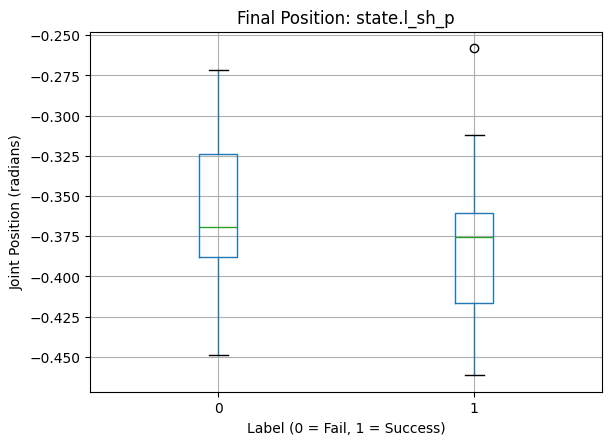

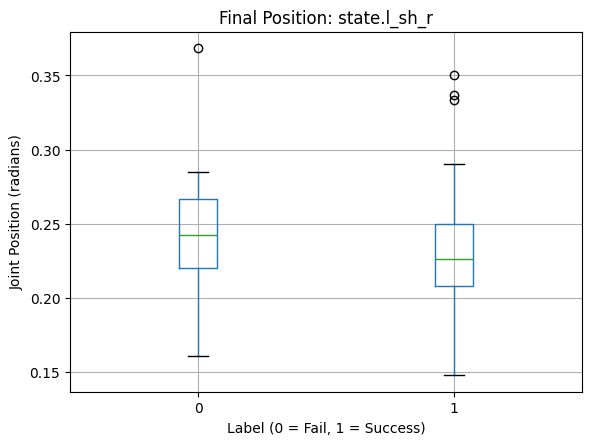

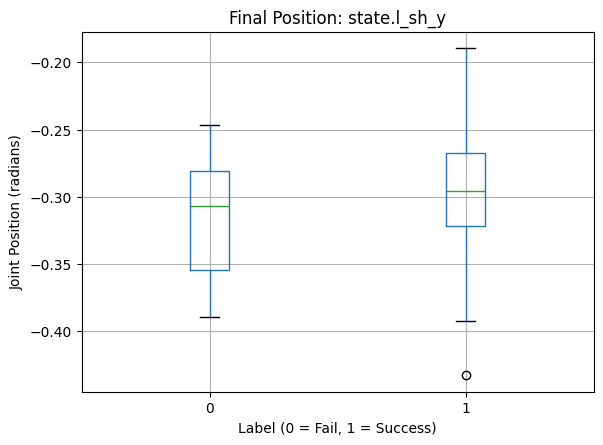

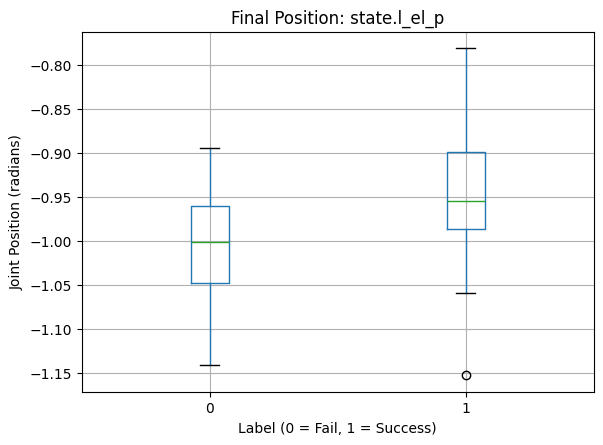

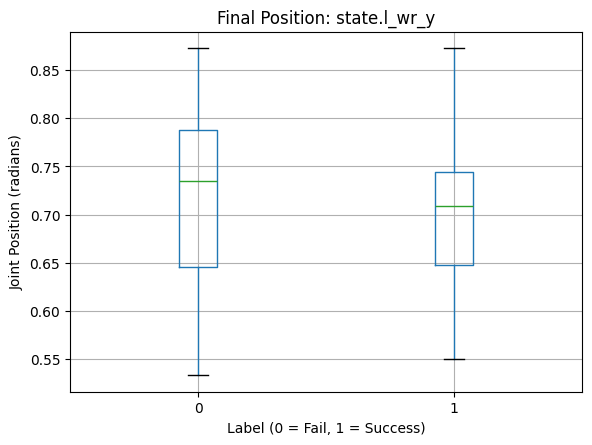

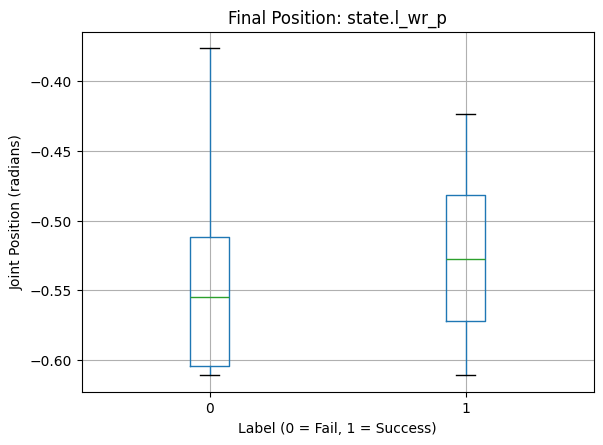

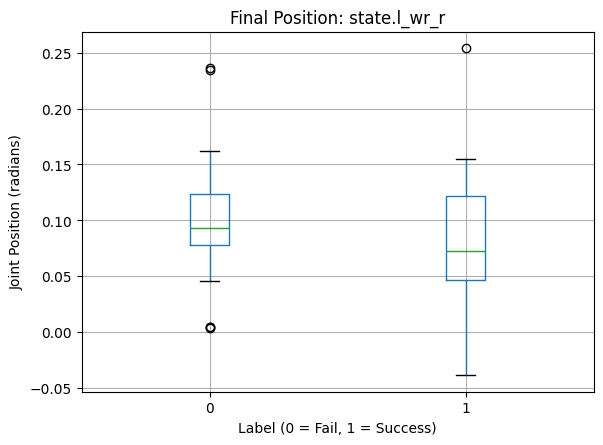

In [44]:
import matplotlib.pyplot as plt

for col in [
    "state.l_sh_p",
    "state.l_sh_r",
    "state.l_sh_y",
    "state.l_el_p",
    "state.l_wr_y",
    "state.l_wr_p",
    "state.l_wr_r"
]:
    joint_df.boxplot(column=col, by="label")

    plt.title(f"Final Position: {col}")
    plt.suptitle("")
    plt.xlabel("Label (0 = Fail, 1 = Success)")
    plt.ylabel("Joint Position (radians)")
    plt.show()

In [45]:
##standardized mean difference (SMD)// numerical comparison 
import numpy as np
import pandas as pd

joint_columns = [
    "state.l_sh_p",
    "state.l_sh_r",
    "state.l_sh_y",
    "state.l_el_p",
    "state.l_wr_y",
    "state.l_wr_p",
    "state.l_wr_r"
]

smd_results = []

for col in joint_columns:
    fail = joint_df[joint_df["label"] == 0][col]
    success = joint_df[joint_df["label"] == 1][col]

    pooled_std = np.sqrt(
        ((len(fail)-1)*fail.var() +
         (len(success)-1)*success.var())
        / (len(fail)+len(success)-2)
    )

    smd = (success.mean() - fail.mean()) / pooled_std

    smd_results.append({
        "joint": col,
        "fail_mean": fail.mean(),
        "success_mean": success.mean(),
        "SMD": smd,
        "abs_SMD": abs(smd)
    })

smd_df = pd.DataFrame(smd_results).sort_values(
    "abs_SMD", ascending=False
)

display(smd_df.round(4))

,joint,fail_mean,success_mean,SMD,abs_SMD
3,state.l_el_p,-1.0026,-0.9486,0.7186,0.7186
0,state.l_sh_p,-0.3589,-0.3823,-0.4884,0.4884
4,state.l_wr_y,0.7303,0.6992,-0.3838,0.3838
2,state.l_sh_y,-0.3161,-0.2991,0.3579,0.3579
6,state.l_wr_r,0.1000,0.0780,-0.3505,0.3505
5,state.l_wr_p,-0.5385,-0.5247,0.2131,0.2131
1,state.l_sh_r,0.2449,0.2369,-0.1739,0.1739


In [46]:
## The total accumulated elbow-angle changes while the robot holds the object.
phase_movement_results = []

for eid, df in episodes.items():
    result = detect_phases(df)

    start = result["grasp_idx"]
    end = result["release_idx"]

    col = "state.l_el_p"

    movement = (
        df[col].iloc[start:end+1].diff().abs().sum()
    )

    phase_movement_results.append({
        "episode": eid,
        "label": labels[eid],
        "elbow_movement": movement
    })

phase_df = pd.DataFrame(phase_movement_results)

display(
    phase_df.groupby("label")["elbow_movement"]
    .agg(["count", "mean", "median", "min", "max"])
)

,count,mean,median,min,max
label,,,,,
0,21,0.847303,0.817995,0.655010,1.145788
1,27,0.917681,0.922881,0.666754,1.282599


In [47]:
##SMD for elbow movement
fail = phase_df[phase_df["label"] == 0]["elbow_movement"]
success = phase_df[phase_df["label"] == 1]["elbow_movement"]

pooled_std = np.sqrt(
    ((len(fail)-1)*fail.var() +
     (len(success)-1)*success.var())
    / (len(fail)+len(success)-2)
)

smd = (success.mean() - fail.mean()) / pooled_std

print("Elbow movement SMD:", round(smd, 4))

Elbow movement SMD: 0.4822


In [48]:
##compare movement across all seven left-arm joints
movement_results = []

for eid, df in episodes.items():
    result = detect_phases(df)

    start = result["grasp_idx"]
    end = result["release_idx"]

    row = {
        "episode": eid,
        "label": labels[eid]
    }

    for col in joint_columns:
        movement = (
            df[col].iloc[start:end+1]
            .diff()
            .abs()
            .sum()
        )

        row[col] = movement

    movement_results.append(row)

movement_df = pd.DataFrame(movement_results)

display(
    movement_df.groupby("label")
    .mean(numeric_only=True).T
)

label,0,1
state.l_sh_p,0.335373,0.329477
state.l_sh_r,0.406925,0.453632
state.l_sh_y,0.437931,0.467925
state.l_el_p,0.847303,0.917681
state.l_wr_y,0.522796,0.555044
state.l_wr_p,0.508458,0.552545
state.l_wr_r,0.398788,0.422262


In [49]:
##SMD for all seven movement features
movement_smd_results = []

for col in joint_columns:
    fail = movement_df[movement_df["label"] == 0][col]
    success = movement_df[movement_df["label"] == 1][col]

    pooled_std = np.sqrt(
        ((len(fail)-1)*fail.var() +
         (len(success)-1)*success.var())
        / (len(fail)+len(success)-2)
    )

    smd = (success.mean() - fail.mean()) / pooled_std

    movement_smd_results.append({
        "joint": col,
        "fail_mean": fail.mean(),
        "success_mean": success.mean(),
        "SMD": smd,
        "abs_SMD": abs(smd)
    })

movement_smd_df = pd.DataFrame(
    movement_smd_results
).sort_values("abs_SMD", ascending=False)

display(movement_smd_df.round(4))

,joint,fail_mean,success_mean,SMD,abs_SMD
1,state.l_sh_r,0.4069,0.4536,0.8039,0.8039
3,state.l_el_p,0.8473,0.9177,0.4822,0.4822
5,state.l_wr_p,0.5085,0.5525,0.4426,0.4426
6,state.l_wr_r,0.3988,0.4223,0.3616,0.3616
4,state.l_wr_y,0.5228,0.5550,0.3550,0.3550
2,state.l_sh_y,0.4379,0.4679,0.2985,0.2985
0,state.l_sh_p,0.3354,0.3295,-0.0865,0.0865


In [50]:
from src.features import extract_features

eid = "000002"

features = extract_features(episodes[eid])

for name, value in features.items():
    print(f"{name:20s}: {value}")

duration            : 17.166666666666668
reach_time          : 9.7
carry_time          : 4.200000000000001
return_time         : 3.2666666666666675
reach_ratio         : 0.5650485436893203
mean_speed          : 0.7037983805825244
max_speed           : 2.0241351
carry_speed         : 0.7938921252380953
path_length         : 12.081872200000003
track_err           : 0.031509519505454046
max_track_err       : 0.20705286000000006
n_grasps            : 1


In [51]:
##complete feature extraction 
from src.features import build_table

features_df = build_table(episodes, labels)

print("Shape:", features_df.shape)
display(features_df.head())

Shape: (48, 14)


,episode,duration,reach_time,carry_time,return_time,reach_ratio,mean_speed,max_speed,carry_speed,path_length,track_err,max_track_err,n_grasps,label
0,000002,17.166667,9.700000,4.200000,3.266667,0.565049,0.703798,2.024135,0.793892,12.081872,0.031510,0.207053,1,1
1,000009,12.933333,6.533333,3.700000,2.700000,0.505155,0.714439,2.165070,0.810930,9.240077,0.032405,0.212457,1,1
2,000014,9.933333,4.433333,3.333333,2.166667,0.446309,0.821931,2.702206,0.982694,8.164517,0.038020,0.228291,1,1
3,000016,12.533333,5.433333,4.800000,2.300000,0.433511,0.729539,3.913087,0.798794,9.143557,0.034607,0.236676,1,1
4,000017,12.066667,4.500000,5.233333,2.333333,0.372928,0.761166,2.978321,0.720991,9.184733,0.037106,0.276945,1,1


In [ ]:
##check missing values
display(
    features_df.isna().sum()
)

episode          0
duration         0
reach_time       0
carry_time       0
return_time      0
reach_ratio      0
mean_speed       0
max_speed        0
carry_speed      0
path_length      0
track_err        0
max_track_err    0
n_grasps         0
label            0
dtype: int64

In [53]:
##check whether any numerical values are infinite
numeric_df = features_df.select_dtypes(include="number")

print("Infinite values:", np.isinf(numeric_df).sum().sum())

Infinite values: 0


In [67]:
from src.config import HOLDOUT_IDS, DATA_HOLDOUT

holdout_ids = []

for folder in ["success", "fail"]:
    files = sorted((DATA_HOLDOUT / folder).glob("*.csv"))
    holdout_ids.extend([
        f.stem.replace("episode_", "")
        for f in files
    ])

HOLDOUT_IDS.parent.mkdir(parents=True, exist_ok=True)

with open(HOLDOUT_IDS, "w") as f:
    f.write("\n".join(sorted(holdout_ids)) + "\n")

print("Saved holdout IDs:")
print(sorted(holdout_ids))

Saved holdout IDs:
['000001', '000003', '000024', '000025', '000026', '000031', '000035', '000040']


In [68]:
##feature quality analysis
# Exclude holdout episodes first
holdout_ids = set(['000001', '000003', '000024', '000025', '000026', '000031', '000035', '000040'])  # use your actual holdout IDs
dev_df = features_df[~features_df["episode"].isin(holdout_ids)].copy()

# Compare feature statistics by label
feature_cols = [
    c for c in dev_df.select_dtypes(include="number").columns
    if c != "label"
]

comparison = dev_df.groupby("label")[feature_cols].agg(
    ["mean", "std"]
)

display(comparison.T)

label                       0          1
duration      mean  11.533333  10.901449
              std    1.420241   1.841263
reach_time    mean   5.037255   4.757971
              std    1.164873   1.292293
carry_time    mean   4.078431   3.985507
              std    0.828229   0.658114
return_time   mean   2.417647   2.157971
              std    0.402271   0.467123
reach_ratio   mean   0.435276   0.432468
              std    0.074161   0.047757
mean_speed    mean   0.782554   0.836732
              std    0.120835   0.090773
max_speed     mean   2.343523   2.676192
              std    0.436795   0.521090
carry_speed   mean   0.879861   0.946882
              std    0.209691   0.154320
path_length   mean   8.898845   9.001033
              std    0.821179   0.880546
track_err     mean   0.036333   0.038757
              std    0.005660   0.004109
max_track_err mean   0.222002   0.247976
              std    0.036170   0.043736
n_grasps      mean   1.000000   1.000000
              std    0.000000   0.000000

In [69]:
##compare success vs fail(exclude holdout episodes)
import numpy as np
import pandas as pd

# Select numerical features, excluding label
feature_cols = [
    col for col in dev_df.select_dtypes(include="number").columns
    if col != "label"
]

# Compare mean and standard deviation
comparison = dev_df.groupby("label")[feature_cols].agg(
    ["mean", "std"]
)

# Display results
display(comparison.T)

label                       0          1
duration      mean  11.533333  10.901449
              std    1.420241   1.841263
reach_time    mean   5.037255   4.757971
              std    1.164873   1.292293
carry_time    mean   4.078431   3.985507
              std    0.828229   0.658114
return_time   mean   2.417647   2.157971
              std    0.402271   0.467123
reach_ratio   mean   0.435276   0.432468
              std    0.074161   0.047757
mean_speed    mean   0.782554   0.836732
              std    0.120835   0.090773
max_speed     mean   2.343523   2.676192
              std    0.436795   0.521090
carry_speed   mean   0.879861   0.946882
              std    0.209691   0.154320
path_length   mean   8.898845   9.001033
              std    0.821179   0.880546
track_err     mean   0.036333   0.038757
              std    0.005660   0.004109
max_track_err mean   0.222002   0.247976
              std    0.036170   0.043736
n_grasps      mean   1.000000   1.000000
              std    0.000000   0.000000

In [70]:
##Calculate feature separation (SMD)
results = []

fail = dev_df[dev_df["label"] == 0]
success = dev_df[dev_df["label"] == 1]

for col in feature_cols:
    mean_fail = fail[col].mean()
    mean_success = success[col].mean()

    std_fail = fail[col].std()
    std_success = success[col].std()

    # Pooled standard deviation
    pooled_std = np.sqrt(
        (std_fail**2 + std_success**2) / 2
    )

    smd = (
        (mean_success - mean_fail) / pooled_std
        if pooled_std != 0 else 0
    )

    results.append({
        "feature": col,
        "fail_mean": mean_fail,
        "success_mean": mean_success,
        "SMD": smd,
        "abs_SMD": abs(smd)
    })

smd_df = pd.DataFrame(results)
smd_df = smd_df.sort_values("abs_SMD", ascending=False)

display(smd_df.round(4))

,feature,fail_mean,success_mean,SMD,abs_SMD
6,max_speed,2.3435,2.6762,0.6919,0.6919
10,max_track_err,0.2220,0.2480,0.6472,0.6472
3,return_time,2.4176,2.1580,-0.5957,0.5957
5,mean_speed,0.7826,0.8367,0.5070,0.5070
9,track_err,0.0363,0.0388,0.4901,0.4901
0,duration,11.5333,10.9014,-0.3843,0.3843
7,carry_speed,0.8799,0.9469,0.3640,0.3640
1,reach_time,5.0373,4.7580,-0.2270,0.2270
2,carry_time,4.0784,3.9855,-0.1242,0.1242
8,path_length,8.8988,9.0010,0.1200,0.1200


In [71]:
##constant features
for col in feature_cols:
    if dev_df[col].nunique() <= 1:
        print(f"Constant feature: {col}")

Constant feature: n_grasps


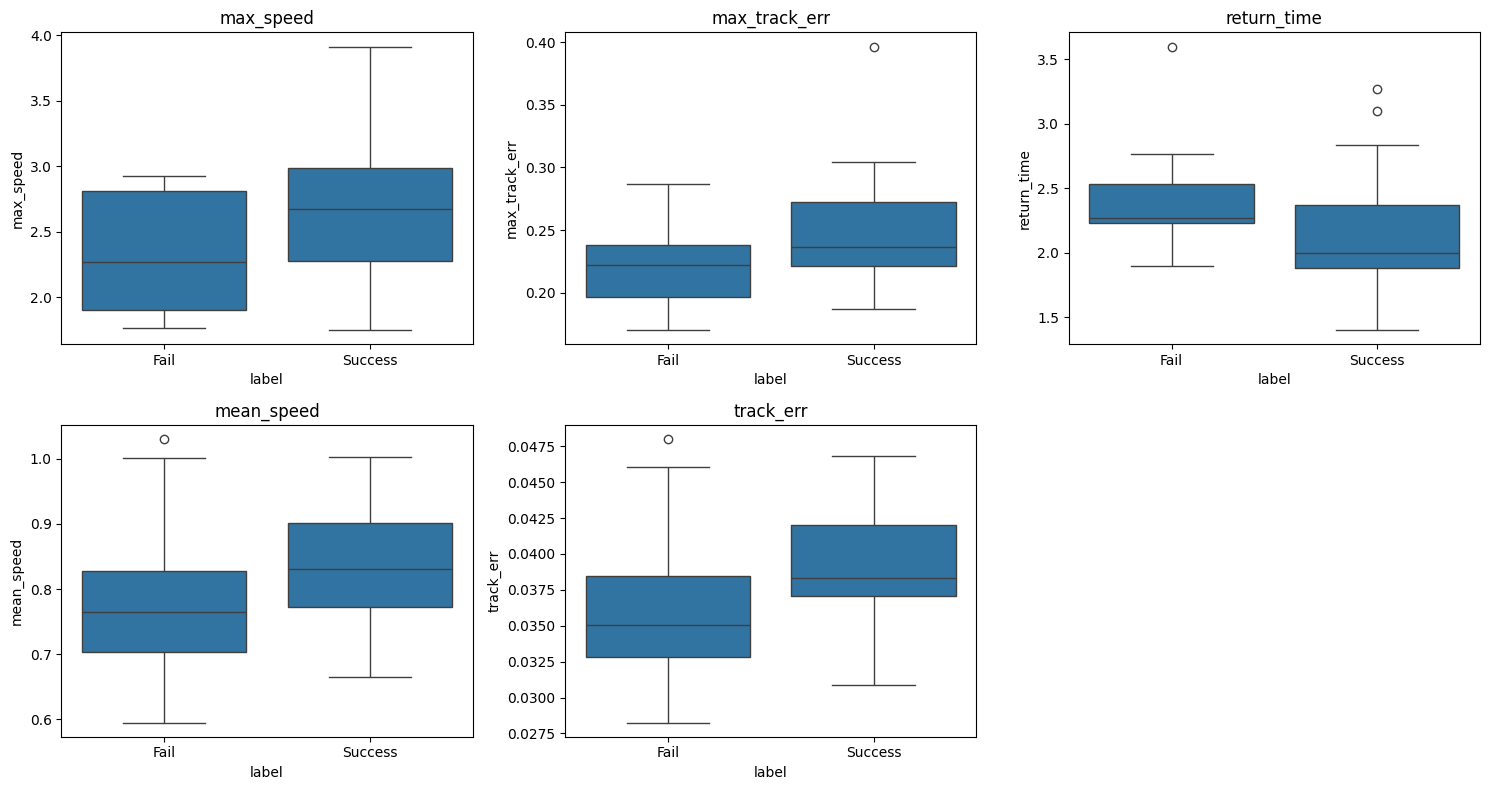

In [72]:
import matplotlib.pyplot as plt
import seaborn as sns

selected_features = [
    "max_speed",
    "max_track_err",
    "return_time",
    "mean_speed",
    "track_err"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, feature in zip(axes.flatten(), selected_features):
    sns.boxplot(
        data=dev_df,
        x="label",
        y=feature,
        ax=ax
    )

    ax.set_title(feature)
    ax.set_xticks([0, 1], ["Fail", "Success"])

# Hide unused sixth plot
axes.flatten()[-1].axis("off")

plt.tight_layout()
plt.show()

In [73]:
return_analysis = dev_df.groupby("label")["return_time"].agg(
    ["count", "mean", "std", "min", "median", "max"]
)

display(return_analysis)

,count,mean,std,min,median,max
label,,,,,,
0,17,2.417647,0.402271,1.9,2.266667,3.600000
1,23,2.157971,0.467123,1.4,2.000000,3.266667


In [74]:
display(
    dev_df[["episode", "label", "return_time"]]
    .sort_values("return_time")
    .reset_index(drop=True)
)

,episode,label,return_time
0,000038,1,1.400000
1,000037,1,1.700000
2,000039,1,1.700000
3,000047,1,1.700000
4,000046,1,1.833333
5,000033,1,1.866667
6,000043,1,1.900000
7,000042,1,1.900000
8,000011,0,1.900000
9,000022,1,1.933333


**Can return time classify success by itself?**

In [75]:
from sklearn.metrics import confusion_matrix, classification_report

threshold = 2.2

y_true = dev_df["label"]
y_pred = (dev_df["return_time"] < threshold).astype(int)

print(confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred))

[[13  4]
 [ 8 15]]
              precision    recall  f1-score   support

           0       0.62      0.76      0.68        17
           1       0.79      0.65      0.71        23

    accuracy                           0.70        40
   macro avg       0.70      0.71      0.70        40
weighted avg       0.72      0.70      0.70        40



In [76]:
##joint-level movement features
from src.config import state

joint_features = ["l_el_p", "l_sh_r", "l_wr_p"]

results = []

for joint in joint_features:
    col = state([joint])[0]

    for label, name in [(0, "Fail"), (1, "Success")]:
        values = []

        for eid in dev_df["episode"]:
            df = episodes[eid]

            # Find grasp and release frames
            ph = detect_phases(df)

            # Joint movement during grasp-to-release
            start = ph["grasp_idx"]
            end = ph["release_idx"]

            movement = (
                df[col].iloc[start:end+1].diff().abs().sum()
            )

            if labels[eid] == label:
                values.append(movement)

        results.append({
            "joint": joint,
            "class": name,
            "mean_movement": np.mean(values),
            "std": np.std(values, ddof=1)
        })

display(pd.DataFrame(results).round(4))

,joint,class,mean_movement,std
0,l_el_p,Fail,0.8405,0.1442
1,l_el_p,Success,0.8986,0.1391
2,l_sh_r,Fail,0.4116,0.0575
3,l_sh_r,Success,0.4588,0.0614
4,l_wr_p,Fail,0.5192,0.1110
5,l_wr_p,Success,0.5514,0.0903


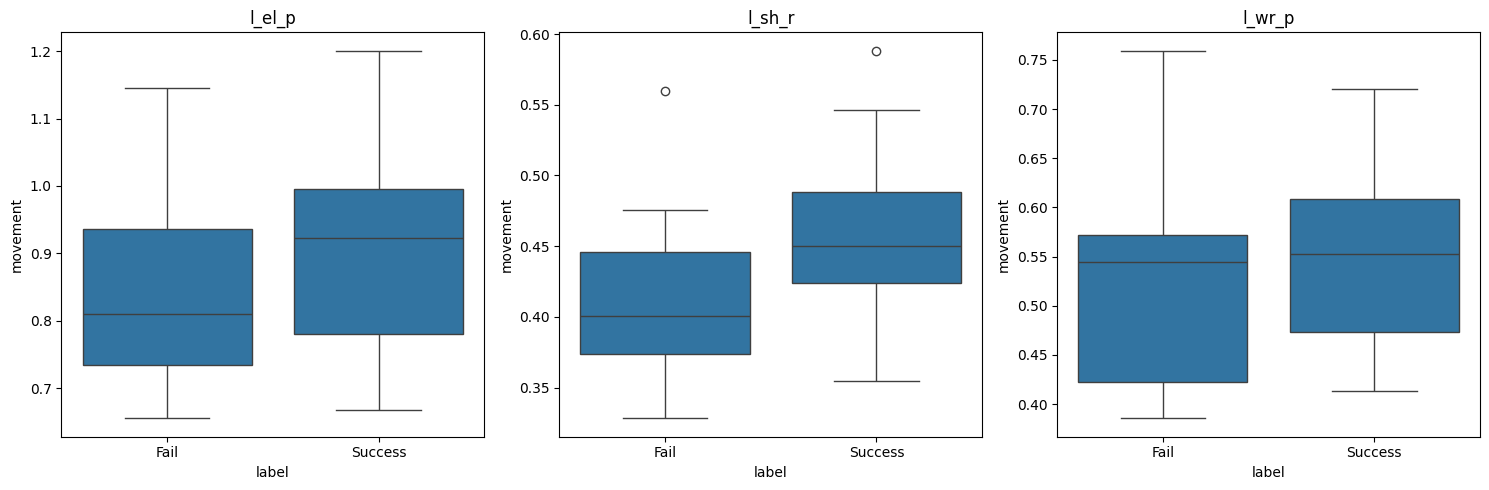

In [77]:
import matplotlib.pyplot as plt
import seaborn as sns

joint_movement_data = []

for eid in dev_df["episode"]:
    df = episodes[eid]
    ph = detect_phases(df)

    start = ph["grasp_idx"]
    end = ph["release_idx"]

    for joint in ["l_el_p", "l_sh_r", "l_wr_p"]:
        col = state([joint])[0]

        movement = (
            df[col].iloc[start:end+1].diff().abs().sum()
        )

        joint_movement_data.append({
            "episode": eid,
            "label": labels[eid],
            "joint": joint,
            "movement": movement
        })

joint_df = pd.DataFrame(joint_movement_data)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, joint in zip(axes, ["l_el_p", "l_sh_r", "l_wr_p"]):
    subset = joint_df[joint_df["joint"] == joint]

    sns.boxplot(
        data=subset,
        x="label",
        y="movement",
        ax=ax
    )

    ax.set_title(joint)
    ax.set_xticks([0, 1], ["Fail", "Success"])

plt.tight_layout()
plt.show()

In [6]:
import os

print(os.getcwd())
print(os.listdir())

c:\Users\akifn\Documents\MachineLearningICPBL\notebooks
['akif_data_exploration.ipynb', 'README.md']


In [7]:
import os
os.chdir("..")

In [8]:
print(os.getcwd())

c:\Users\akifn\Documents\MachineLearningICPBL


In [10]:
from src.config import DATA_RAW
from src.load import load_folder

episodes, labels = load_folder(DATA_RAW)

print("Total episodes:", len(episodes))
print("Episode 000002 exists:", "000002" in episodes)

Total episodes: 48
Episode 000002 exists: True


In [11]:
import importlib
import src.features

importlib.reload(src.features)

test_result = src.features.extract_features(episodes["000002"])

print("Shoulder roll movement:",
      test_result["shoulder_roll_movement"])

Shoulder roll movement: 0.37927675200000005


In [12]:
import importlib
import src.features

importlib.reload(src.features)

test_result = src.features.extract_features(episodes["000002"])

print(test_result.keys())

dict_keys(['duration', 'reach_time', 'carry_time', 'return_time', 'reach_ratio', 'mean_speed', 'max_speed', 'carry_speed', 'path_length', 'track_err', 'max_track_err', 'n_grasps', 'shoulder_roll_movement'])


In [13]:
import src.features

print("Feature exists:",
      hasattr(src.features, "shoulder_roll_movement"))

print("Registered features:")
print([f.__name__ for f in src.features.FEATURE_FUNCTIONS])

Feature exists: True
Registered features:
['duration', 'reach_time', 'carry_time', 'return_time', 'reach_ratio', 'mean_speed', 'max_speed', 'carry_speed', 'path_length', 'track_err', 'max_track_err', 'n_grasps', 'shoulder_roll_movement']


In [14]:
from src.features import build_table

features_df = build_table(episodes, labels)

print(features_df.shape)
print(features_df.columns.tolist())

(48, 15)
['episode', 'duration', 'reach_time', 'carry_time', 'return_time', 'reach_ratio', 'mean_speed', 'max_speed', 'carry_speed', 'path_length', 'track_err', 'max_track_err', 'n_grasps', 'shoulder_roll_movement', 'label']


In [15]:
from pathlib import Path
from src.config import HOLDOUT_IDS

holdout_ids = set(
    Path(HOLDOUT_IDS).read_text().split()
)

dev_df = features_df[
    ~features_df["episode"].isin(holdout_ids)
].copy()

print(dev_df.groupby("label")["shoulder_roll_movement"].agg(
    ["count", "mean", "std", "min", "max"]
))

       count      mean       std       min       max
label                                               
0         17  0.411614  0.057490  0.328224  0.559615
1         23  0.458754  0.061363  0.354637  0.588186


In [16]:
##SMD
fail = dev_df[dev_df["label"] == 0]["shoulder_roll_movement"]
success = dev_df[dev_df["label"] == 1]["shoulder_roll_movement"]

pooled_std = (
    ((len(fail) - 1) * fail.var() +
     (len(success) - 1) * success.var())
    / (len(fail) + len(success) - 2)
) ** 0.5

smd = (success.mean() - fail.mean()) / pooled_std

print("SMD:", round(smd, 4))

SMD: 0.7888


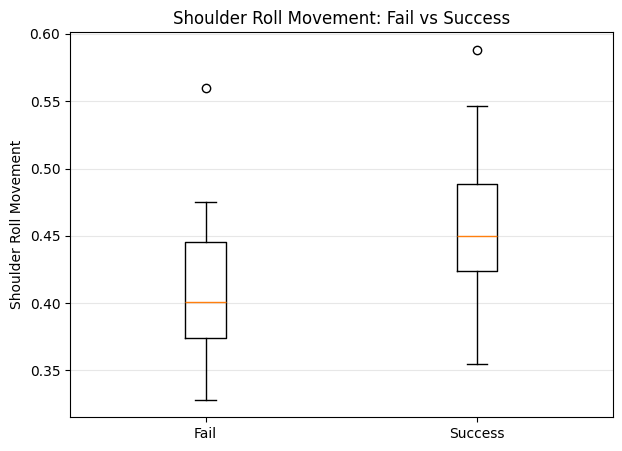

In [17]:
import matplotlib.pyplot as plt

fail = dev_df[dev_df["label"] == 0]["shoulder_roll_movement"]
success = dev_df[dev_df["label"] == 1]["shoulder_roll_movement"]

plt.figure(figsize=(7, 5))
plt.boxplot(
    [fail, success],
    tick_labels=["Fail", "Success"]
)
plt.ylabel("Shoulder Roll Movement")
plt.title("Shoulder Roll Movement: Fail vs Success")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [21]:
import pandas as pd 

feature_cols = [
    col for col in dev_df.select_dtypes(include="number").columns
    if col != "label"
]

results = []

for col in feature_cols:
    fail = dev_df[dev_df["label"] == 0][col].dropna()
    success = dev_df[dev_df["label"] == 1][col].dropna()

    pooled_std = (
        ((len(fail) - 1) * fail.var() +
         (len(success) - 1) * success.var())
        / (len(fail) + len(success) - 2)
    ) ** 0.5

    smd = (success.mean() - fail.mean()) / pooled_std

    results.append({
        "feature": col,
        "SMD": smd,
        "abs_SMD": abs(smd)
    })

smd_df = pd.DataFrame(results).sort_values(
    "abs_SMD", ascending=False
)

print(smd_df.to_string(index=False))

               feature       SMD  abs_SMD
shoulder_roll_movement  0.788782 0.788782
             max_speed  0.682570 0.682570
         max_track_err  0.637841 0.637841
           return_time -0.588860 0.588860
            mean_speed  0.518502 0.518502
             track_err  0.502552 0.502552
              duration -0.376811 0.376811
           carry_speed  0.372905 0.372905
            reach_time -0.225186 0.225186
            carry_time -0.126503 0.126503
           path_length  0.119371 0.119371
           reach_ratio -0.046562 0.046562
              n_grasps       NaN      NaN


C:\Users\akifn\AppData\Local\Temp\ipykernel_31576\3606769672.py:20: RuntimeWarning: invalid value encountered in scalar divide
  smd = (success.mean() - fail.mean()) / pooled_std


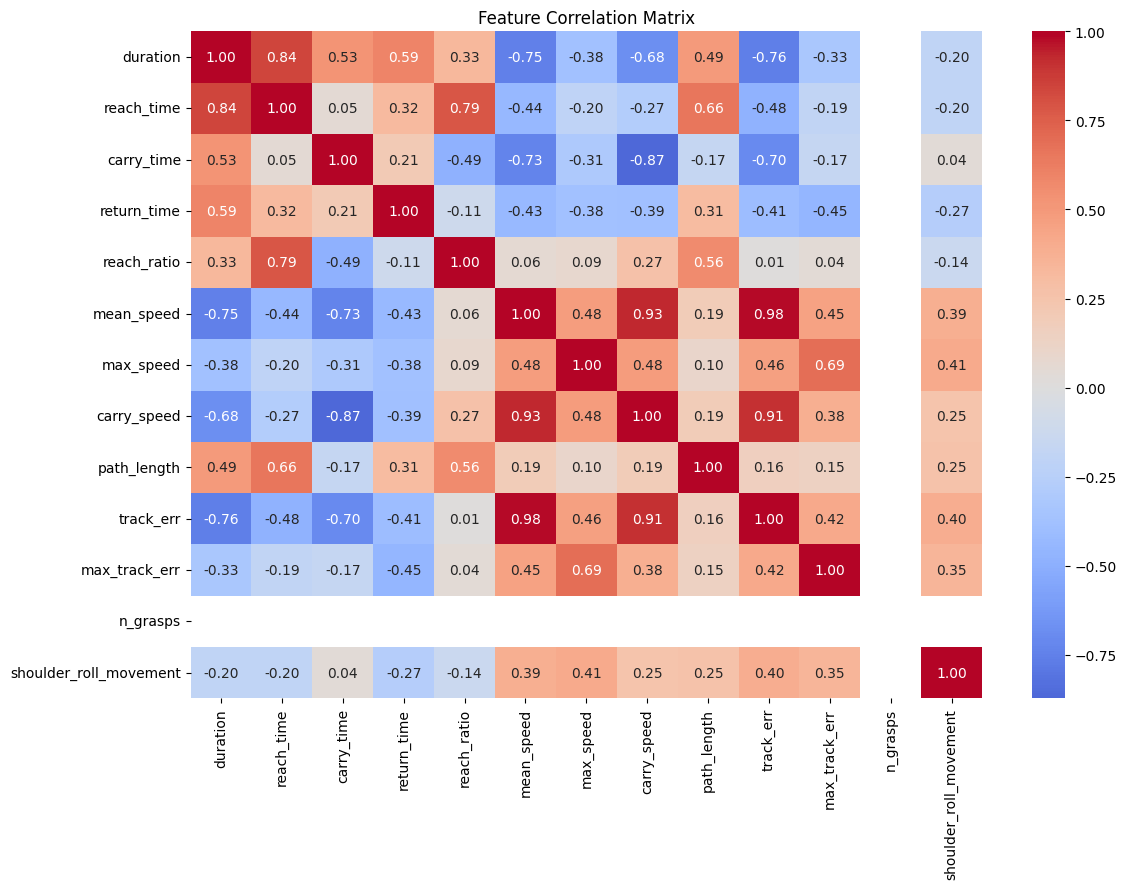

In [22]:
## Check feature redundancy
import matplotlib.pyplot as plt
import seaborn as sns

corr = dev_df.drop(columns=["episode", "label"]).corr()

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [23]:
##compare feature combinations
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
import numpy as np

baseline_features = [
    "max_speed",
    "max_track_err",
    "return_time",
    "mean_speed"
]

features_with_shoulder = baseline_features + [
    "shoulder_roll_movement"
]

X = dev_df[baseline_features]
X_shoulder = dev_df[features_with_shoulder]
y = dev_df["label"]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

scores_baseline = cross_val_score(
    model, X, y, cv=cv, scoring="accuracy"
)

scores_shoulder = cross_val_score(
    model, X_shoulder, y, cv=cv, scoring="accuracy"
)

print("Baseline scores:", scores_baseline)
print("Baseline mean:", scores_baseline.mean())

print("\nWith shoulder roll:", scores_shoulder)
print("With shoulder roll mean:", scores_shoulder.mean())

Baseline scores: [0.75  0.5   0.5   0.625 0.75 ]
Baseline mean: 0.625

With shoulder roll: [0.625 0.625 0.5   0.5   0.625]
With shoulder roll mean: 0.575


In [24]:
## Test individual feature combinations
from itertools import combinations
from sklearn.model_selection import cross_val_score

candidate_features = [
    "max_speed",
    "max_track_err",
    "return_time",
    "mean_speed",
    "shoulder_roll_movement"
]

results = []

for r in range(1, len(candidate_features) + 1):
    for combo in combinations(candidate_features, r):

        X = dev_df[list(combo)]

        scores = cross_val_score(
            model,
            X,
            y,
            cv=cv,
            scoring="accuracy"
        )

        results.append({
            "features": ", ".join(combo),
            "n_features": len(combo),
            "mean_accuracy": scores.mean(),
            "std_accuracy": scores.std()
        })

combination_df = pd.DataFrame(results)

combination_df = combination_df.sort_values(
    "mean_accuracy",
    ascending=False
)

print(combination_df.head(15).to_string(index=False))

                                                  features  n_features  mean_accuracy  std_accuracy
                     max_track_err, shoulder_roll_movement           2          0.700      0.100000
                        mean_speed, shoulder_roll_movement           2          0.675      0.061237
                                             max_track_err           1          0.675      0.150000
           return_time, mean_speed, shoulder_roll_movement           3          0.675      0.100000
max_speed, return_time, mean_speed, shoulder_roll_movement           4          0.675      0.100000
                                    max_speed, return_time           2          0.650      0.093541
                                  max_speed, max_track_err           2          0.650      0.122474
                       return_time, shoulder_roll_movement           2          0.650      0.093541
                                 max_track_err, mean_speed           2          0.650      0.145774


In [25]:
##Check consistency across folds
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

comparisons = {
    "max_track_err": ["max_track_err"],
    "max_track_err + shoulder": [
        "max_track_err",
        "shoulder_roll_movement"
    ]
}

for name, cols in comparisons.items():
    X = dev_df[cols]

    predictions = cross_val_predict(
        model,
        X,
        y,
        cv=cv
    )

    print("\n", name)
    print("Confusion matrix:")
    print(confusion_matrix(y, predictions))
    print(classification_report(
        y,
        predictions,
        target_names=["Fail", "Success"],
        zero_division=0
    ))


 max_track_err
Confusion matrix:
[[ 8  9]
 [ 4 19]]
              precision    recall  f1-score   support

        Fail       0.67      0.47      0.55        17
     Success       0.68      0.83      0.75        23

    accuracy                           0.68        40
   macro avg       0.67      0.65      0.65        40
weighted avg       0.67      0.68      0.66        40


 max_track_err + shoulder
Confusion matrix:
[[10  7]
 [ 5 18]]
              precision    recall  f1-score   support

        Fail       0.67      0.59      0.62        17
     Success       0.72      0.78      0.75        23

    accuracy                           0.70        40
   macro avg       0.69      0.69      0.69        40
weighted avg       0.70      0.70      0.70        40



In [26]:
##Investigate the misclassified episodes
from sklearn.model_selection import cross_val_predict

best_features = [
    "max_track_err",
    "shoulder_roll_movement"
]

X = dev_df[best_features]

predictions = cross_val_predict(
    model,
    X,
    y,
    cv=cv
)

error_df = dev_df[["episode", "label"] + best_features].copy()

error_df["predicted"] = predictions
error_df["correct"] = error_df["label"] == error_df["predicted"]

print("Correct predictions:", error_df["correct"].sum())
print("Incorrect predictions:", (~error_df["correct"]).sum())

print("\nMisclassified episodes:")
print(
    error_df[~error_df["correct"]]
    .sort_values(["label", "episode"])
    .to_string(index=False)
)

Correct predictions: 28
Incorrect predictions: 12

Misclassified episodes:
episode  label  max_track_err  shoulder_roll_movement  predicted  correct
 000010      0       0.211188                0.559615          1    False
 000011      0       0.237348                0.434212          1    False
 000013      0       0.238322                0.445813          1    False
 000018      0       0.232957                0.445574          1    False
 000028      0       0.279551                0.455880          1    False
 000044      0       0.242248                0.475342          1    False
 000045      0       0.287208                0.441786          1    False
 000002      1       0.207053                0.379277          0    False
 000009      1       0.212457                0.354637          0    False
 000014      1       0.228291                0.368060          0    False
 000032      1       0.235881                0.388960          0    False
 000041      1       0.187032        

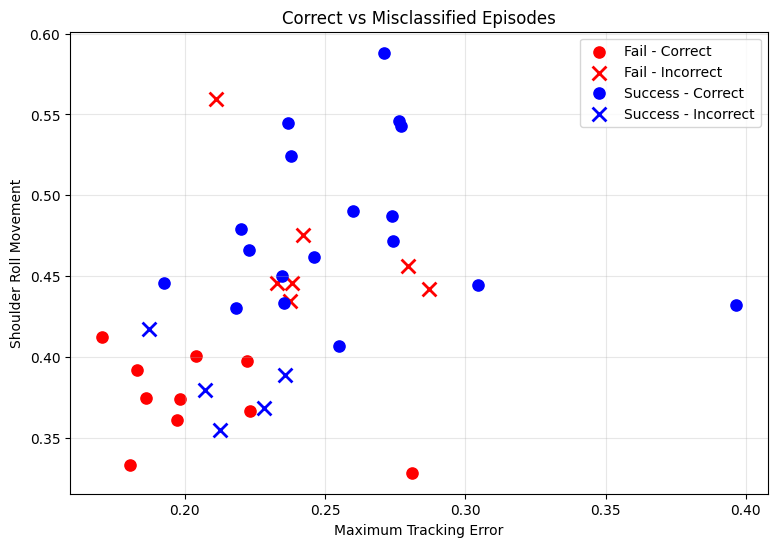

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

for label, name, color in [
    (0, "Fail", "red"),
    (1, "Success", "blue")
]:
    subset = error_df[error_df["label"] == label]

    correct = subset[subset["correct"]]
    incorrect = subset[~subset["correct"]]

    plt.scatter(
        correct["max_track_err"],
        correct["shoulder_roll_movement"],
        color=color,
        label=f"{name} - Correct",
        marker="o",
        s=65
    )

    plt.scatter(
        incorrect["max_track_err"],
        incorrect["shoulder_roll_movement"],
        color=color,
        label=f"{name} - Incorrect",
        marker="x",
        s=100,
        linewidths=2
    )

plt.xlabel("Maximum Tracking Error")
plt.ylabel("Shoulder Roll Movement")
plt.title("Correct vs Misclassified Episodes")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

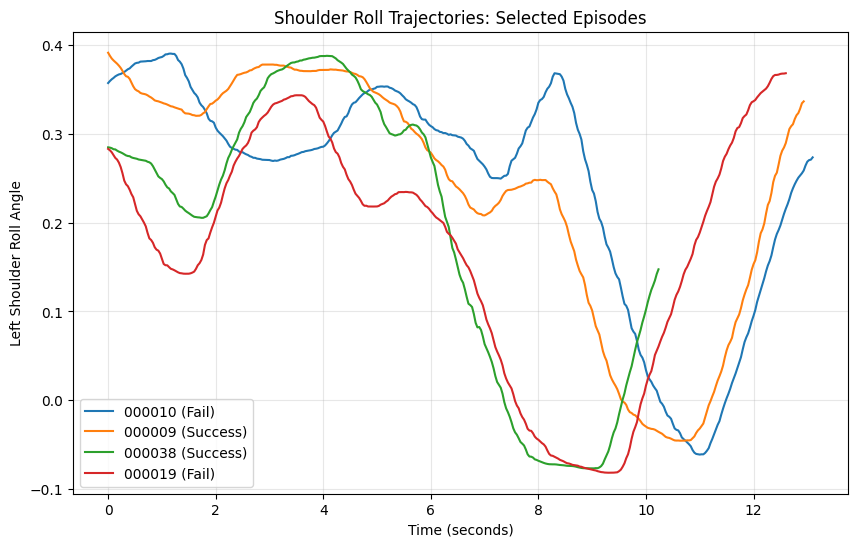

In [28]:
##Plot their shoulder-roll trajectories
import matplotlib.pyplot as plt

episode_ids = ["000010", "000009", "000038", "000019"]

plt.figure(figsize=(10, 6))

for eid in episode_ids:
    df = episodes[eid]

    label = labels[eid]
    outcome = "Success" if label == 1 else "Fail"

    plt.plot(
        df["timestamp"],
        df["state.l_sh_r"],
        label=f"{eid} ({outcome})"
    )

plt.xlabel("Time (seconds)")
plt.ylabel("Left Shoulder Roll Angle")
plt.title("Shoulder Roll Trajectories: Selected Episodes")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [31]:
import pandas as pd
import numpy as np
from src.phases import detect_phases

episode_ids = ["000010", "000009", "000038", "000019"]

rows = []

for eid in episode_ids:
    df = episodes[eid]
    ph = detect_phases(df)

    angle = df["state.l_sh_r"]
    timestamp = df["timestamp"]

    min_idx = angle.idxmin()
    max_idx = angle.idxmax()

    rows.append({
        "episode": eid,
        "label": labels[eid],
        "duration": timestamp.iloc[-1],
        "initial_angle": angle.iloc[0],
        "early_min_0_5s": angle[timestamp <= 5].min(),
        "minimum_angle": angle.min(),
        "time_of_minimum": timestamp.loc[min_idx],
        "final_angle": angle.iloc[-1],
        "grasp_time": timestamp.iloc[ph["grasp_idx"]]
            if ph["grasp_idx"] is not None else np.nan,
        "release_time": timestamp.iloc[ph["release_idx"]]
            if ph["release_idx"] is not None else np.nan
    })

comparison_df = pd.DataFrame(rows)

print(comparison_df.round(3).to_string(index=False))

episode  label  duration  initial_angle  early_min_0_5s  minimum_angle  time_of_minimum  final_angle  grasp_time  release_time
 000010      0    13.100          0.357           0.270         -0.061           11.000        0.274       6.667        10.567
 000009      1    12.933          0.392           0.321         -0.046           10.633        0.337       6.533        10.233
 000038      1    10.233          0.285           0.206         -0.077            9.000        0.148       4.900         8.833
 000019      0    12.600          0.283           0.143         -0.082            9.300        0.368       4.367         9.000


In [34]:
##Investigate all 40 episodes
import numpy as np
import pandas as pd

rows = []

for eid, df in episodes.items():

    if eid in holdout_ids:
        continue

    ph = detect_phases(df)

    angle = df["state.l_sh_r"]
    timestamp = df["timestamp"]

    initial = angle.iloc[0]
    minimum = angle.min()
    final = angle.iloc[-1]

    release_idx = ph["release_idx"]

    release_time = (
        timestamp.iloc[release_idx]
        if release_idx is not None else np.nan
    )

    duration = timestamp.iloc[-1]

    rows.append({
        "episode": eid,
        "label": labels[eid],
        "early_min": angle[timestamp <= 5].min(),
        "minimum_angle": minimum,
        "final_angle": final,
        "return_window": duration - release_time,
        "recovery_fraction": (
            (final - minimum) / (initial - minimum)
            if initial != minimum else np.nan
        )
    })

shoulder_analysis = pd.DataFrame(rows)

numeric_cols = [
    "early_min",
    "minimum_angle",
    "final_angle",
    "return_window",
    "recovery_fraction"
]

print(
    shoulder_analysis.groupby("label")[numeric_cols]
    .agg(["mean", "std", "min", "max"])
    .round(3)
    .to_string()
)

      early_min                      minimum_angle                      final_angle                      return_window                    recovery_fraction                     
           mean    std    min    max          mean    std    min    max        mean    std    min    max          mean    std  min    max              mean    std    min    max
label                                                                                                                                                                           
0         0.184  0.047  0.096  0.273        -0.062  0.042 -0.126  0.001       0.246  0.045  0.161  0.368         2.418  0.402  1.9  3.600             0.919  0.145  0.725  1.234
1         0.220  0.048  0.148  0.321        -0.071  0.033 -0.137 -0.002       0.241  0.052  0.148  0.350         2.158  0.467  1.4  3.267             0.888  0.135  0.620  1.181


In [35]:
##Test whether early_min improves classification
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from src.config import RANDOM_STATE

X = shoulder_analysis[
    ["early_min"]
].copy()

# Use the original development feature table for the other features.
# Assumes your original feature table is named features_df.

In [40]:
from src.features import build_table

features_df = build_table(episodes, labels)

print(features_df.shape)
features_df.head()

(48, 15)


,episode,duration,reach_time,carry_time,return_time,reach_ratio,mean_speed,max_speed,carry_speed,path_length,track_err,max_track_err,n_grasps,shoulder_roll_movement,label
0,000002,17.166667,9.700000,4.200000,3.233333,0.565049,0.703798,2.024135,0.793892,12.081872,0.031510,0.207053,1,0.379277,1
1,000009,12.933333,6.533333,3.700000,2.666667,0.505155,0.714439,2.165070,0.810930,9.240077,0.032405,0.212457,1,0.354637,1
2,000014,9.933333,4.433333,3.333333,2.133333,0.446309,0.821931,2.702206,0.982694,8.164517,0.038020,0.228291,1,0.368060,1
3,000016,12.533333,5.433333,4.800000,2.266667,0.433511,0.729539,3.913087,0.798794,9.143557,0.034607,0.236676,1,0.544419,1
4,000017,12.066667,4.500000,5.233333,2.300000,0.372928,0.761166,2.978321,0.720991,9.184733,0.037106,0.276945,1,0.542694,1


In [41]:
from src.config import HOLDOUT_IDS

holdout_ids = set(
    HOLDOUT_IDS.read_text().split()
)

print("Holdout:", len(holdout_ids))
print("Development:", len(features_df) - len(holdout_ids))

Holdout: 8
Development: 40


In [42]:
dev_df = features_df[
    ~features_df["episode"].astype(str).isin(holdout_ids)
].copy()

print(dev_df.shape)

(40, 15)


In [43]:
##test whether early_min improves our model
dev_df = dev_df.merge(
    shoulder_analysis[["episode", "early_min"]],
    on="episode",
    how="left"
)

print(dev_df.shape)

(40, 16)


In [44]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

feature_sets = {
    "Baseline": [
        "max_track_err",
        "shoulder_roll_movement"
    ],
    "Baseline + early_min": [
        "max_track_err",
        "shoulder_roll_movement",
        "early_min"
    ],
    "Shoulder + early_min": [
        "shoulder_roll_movement",
        "early_min"
    ]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for name, features in feature_sets.items():

    X = dev_df[features]
    y = dev_df["label"]

    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ])

    scores = cross_val_score(
        model, X, y,
        cv=cv,
        scoring="accuracy"
    )

    results.append({
        "model": name,
        "fold_scores": scores.round(3).tolist(),
        "mean_accuracy": scores.mean(),
        "std": scores.std()
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

               model                        fold_scores  mean_accuracy      std
            Baseline [0.625, 0.625, 0.75, 0.625, 0.875]          0.700 0.100000
Baseline + early_min     [0.625, 0.75, 0.5, 0.625, 1.0]          0.700 0.169558
Shoulder + early_min   [0.625, 0.75, 0.625, 0.5, 0.875]          0.675 0.127475


So far, our two-feature model uses:
1. max_track_err
2. shoulder_roll_movement
Now let's investigate how each feature influences the model's prediction.

In [45]:
##Examine logistic regression coefficients
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import pandas as pd

selected_features = [
    "max_track_err",
    "shoulder_roll_movement"
]

X = dev_df[selected_features]
y = dev_df["label"]

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

model.fit(X, y)

coefficients = model.named_steps["classifier"].coef_[0]

importance_df = pd.DataFrame({
    "feature": selected_features,
    "coefficient": coefficients,
    "absolute_coefficient": abs(coefficients)
})

importance_df = importance_df.sort_values(
    "absolute_coefficient",
    ascending=False
)

print(importance_df.to_string(index=False))

               feature  coefficient  absolute_coefficient
shoulder_roll_movement     0.626616              0.626616
         max_track_err     0.449128              0.449128


In [46]:
##Investigate misclassified episodes
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import confusion_matrix
import pandas as pd

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

predictions = cross_val_predict(
    model,
    X,
    y,
    cv=cv
)

misclassified = dev_df.loc[
    predictions != y,
    ["episode", "label"] + selected_features
].copy()

misclassified["predicted"] = predictions[predictions != y]
misclassified["actual"] = misclassified["label"]
misclassified["correct"] = False

print("Confusion matrix:")
print(confusion_matrix(y, predictions))

print("\nMisclassified episodes:")
print(misclassified.to_string(index=False))

Confusion matrix:
[[10  7]
 [ 5 18]]

Misclassified episodes:
episode  label  max_track_err  shoulder_roll_movement  predicted  actual  correct
 000002      1       0.207053                0.379277          0       1    False
 000009      1       0.212457                0.354637          0       1    False
 000014      1       0.228291                0.368060          0       1    False
 000032      1       0.235881                0.388960          0       1    False
 000041      1       0.187032                0.417051          0       1    False
 000010      0       0.211188                0.559615          1       0    False
 000011      0       0.237348                0.434212          1       0    False
 000013      0       0.238322                0.445813          1       0    False
 000018      0       0.232957                0.445574          1       0    False
 000028      0       0.279551                0.455880          1       0    False
 000044      0       0.242248       

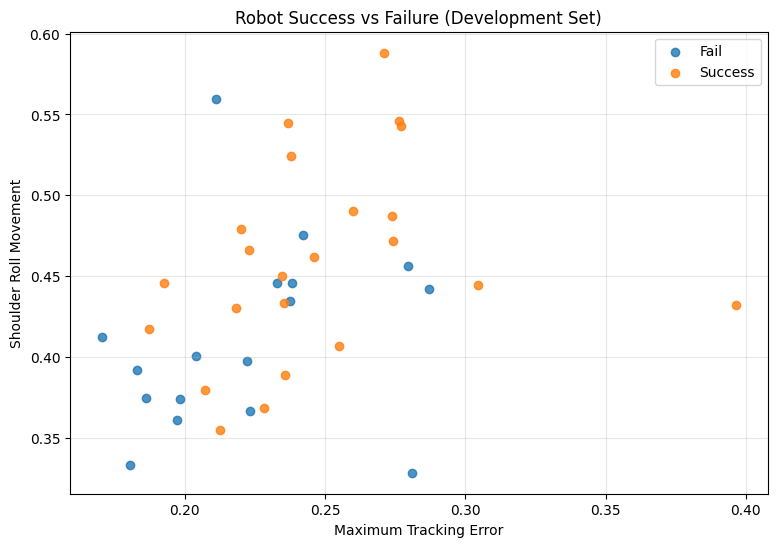

In [47]:
##decision boundary
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

for label, name, color in [
    (0, "Fail", "red"),
    (1, "Success", "green")
]:
    subset = dev_df[dev_df["label"] == label]

    plt.scatter(
        subset["max_track_err"],
        subset["shoulder_roll_movement"],
        label=name,
        alpha=0.8
    )

plt.xlabel("Maximum Tracking Error")
plt.ylabel("Shoulder Roll Movement")
plt.title("Robot Success vs Failure (Development Set)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [48]:
##Investigate the two outliers
outlier_ids = ["000010", "000038", "000019"]

for eid in outlier_ids:
    df = episodes[eid]

    print(f"\nEpisode: {eid}")
    print("Label:", labels[eid])
    print("Frames:", len(df))
    print("Duration:", df["timestamp"].iloc[-1])

    print("\nShoulder roll:")
    print(df["state.l_sh_r"].describe())

    print("\nTracking error:")
    print(df["state.l_el_p"].describe())


Episode: 000010
Label: 0
Frames: 394
Duration: 13.1

Shoulder roll:
count    394.000000
mean       0.243337
std        0.128065
min       -0.061263
25%        0.195127
50%        0.282300
75%        0.335702
max        0.390638
Name: state.l_sh_r, dtype: float64

Tracking error:
count    394.000000
mean      -1.077200
std        0.103080
min       -1.339980
25%       -1.151696
50%       -1.068777
75%       -1.003475
max       -0.898050
Name: state.l_el_p, dtype: float64

Episode: 000038
Label: 1
Frames: 308
Duration: 10.233333333333333

Shoulder roll:
count    308.000000
mean       0.189593
std        0.161026
min       -0.076843
25%        0.037642
50%        0.242944
75%        0.314059
max        0.388097
Name: state.l_sh_r, dtype: float64

Tracking error:
count    308.000000
mean      -1.017122
std        0.137634
min       -1.310930
25%       -1.104550
50%       -1.048164
75%       -0.935393
max       -0.716465
Name: state.l_el_p, dtype: float64

Episode: 000019
Label: 0
Frames: 

In [50]:
##Check tracking error by joint
import numpy as np
import pandas as pd

from src.config import ARM_JOINTS, state, action

rows = []

for eid, df in episodes.items():

    if eid in holdout_ids:
        continue

    for joint in ARM_JOINTS:

        s = df[state([joint])].to_numpy()
        a = df[action([joint])].to_numpy()

        error = np.abs(s - a).mean()

        rows.append({
            "episode": eid,
            "label": labels[eid],
            "joint": joint,
            "tracking_error": error
        })

joint_errors = pd.DataFrame(rows)

joint_summary = joint_errors.groupby(
    ["joint", "label"]
)["tracking_error"].mean().unstack()

joint_summary.columns = ["Fail", "Success"]

joint_summary["difference"] = (
    joint_summary["Success"] - joint_summary["Fail"]
)

print(joint_summary.round(4).to_string())

          Fail  Success  difference
joint                              
l_el_p  0.0295   0.0299      0.0004
l_sh_p  0.0614   0.0616      0.0002
l_sh_r  0.0636   0.0701      0.0065
l_sh_y  0.0194   0.0206      0.0012
l_wr_p  0.0216   0.0262      0.0046
l_wr_r  0.0236   0.0271      0.0035
l_wr_y  0.0352   0.0358      0.0007


In [51]:
##Compare tracking error by task phase
import numpy as np
import pandas as pd

from src.config import ARM_JOINTS, state, action

rows = []

for eid, df in episodes.items():

    if eid in holdout_ids:
        continue

    ph = detect_phases(df)

    if ph["grasp_idx"] is None or ph["release_idx"] is None:
        continue

    # Phase boundaries
    phases = {
        "reach": (0, ph["grasp_idx"]),
        "carry": (ph["grasp_idx"], ph["release_idx"]),
        "return": (ph["release_idx"], len(df) - 1)
    }

    for phase_name, (start, end) in phases.items():

        s = df[state(ARM_JOINTS)].iloc[start:end+1].to_numpy()
        a = df[action(ARM_JOINTS)].iloc[start:end+1].to_numpy()

        error = np.abs(s - a).mean()

        rows.append({
            "episode": eid,
            "label": labels[eid],
            "phase": phase_name,
            "tracking_error": error
        })

phase_errors = pd.DataFrame(rows)

phase_summary = phase_errors.groupby(
    ["phase", "label"]
)["tracking_error"].agg(["mean", "std"])

print(phase_summary.round(4).to_string())

                mean     std
phase  label                
carry  0      0.0405  0.0095
       1      0.0431  0.0065
reach  0      0.0285  0.0056
       1      0.0289  0.0042
return 0      0.0481  0.0069
       1      0.0536  0.0066


In [53]:
##Test return-phase tracking error
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create a return-phase feature table
return_df = phase_errors[
    phase_errors["phase"] == "return"
][["episode", "tracking_error"]].copy()

return_df = return_df.rename(
    columns={"tracking_error": "return_track_err"}
)

test_df = dev_df.merge(
    return_df,
    on="episode",
    how="left"
)

feature_sets = {
    "Current baseline": [
        "max_track_err",
        "shoulder_roll_movement"
    ],
    "Baseline + return error": [
        "max_track_err",
        "shoulder_roll_movement",
        "return_track_err"
    ],
    "Shoulder + return error": [
        "shoulder_roll_movement",
        "return_track_err"
    ],
    "Return error only": [
        "return_track_err"
    ]
}

results = []

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for name, features in feature_sets.items():

    X_test = test_df[features]
    y_test = test_df["label"]

    model_test = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ])

    scores = cross_val_score(
        model_test,
        X_test,
        y_test,
        cv=cv,
        scoring="accuracy"
    )

    results.append({
        "model": name,
        "fold_scores": scores.round(3).tolist(),
        "mean_accuracy": round(scores.mean(), 3),
        "std": round(scores.std(), 3)
    })

print(pd.DataFrame(results).to_string(index=False))

                  model                        fold_scores  mean_accuracy   std
       Current baseline [0.625, 0.625, 0.75, 0.625, 0.875]          0.700 0.100
Baseline + return error [0.625, 0.625, 0.625, 0.625, 0.75]          0.650 0.050
Shoulder + return error  [0.625, 0.625, 0.625, 0.75, 0.75]          0.675 0.061
      Return error only    [0.75, 0.75, 0.625, 0.75, 0.75]          0.725 0.050


In [54]:
##Compare classification errors
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report

feature_sets = {
    "Baseline": [
        "max_track_err",
        "shoulder_roll_movement"
    ],
    "Return error": [
        "return_track_err"
    ]
}

for name, features in feature_sets.items():

    X_test = test_df[features]
    y_test = test_df["label"]

    model_test = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ])

    predictions = cross_val_predict(
        model_test,
        X_test,
        y_test,
        cv=cv
    )

    print(f"\n===== {name} =====")
    print("Confusion matrix:")
    print(confusion_matrix(y_test, predictions))

    print("\nClassification report:")
    print(classification_report(
        y_test,
        predictions,
        target_names=["Fail", "Success"]
    ))


===== Baseline =====
Confusion matrix:
[[10  7]
 [ 5 18]]

Classification report:
              precision    recall  f1-score   support

        Fail       0.67      0.59      0.62        17
     Success       0.72      0.78      0.75        23

    accuracy                           0.70        40
   macro avg       0.69      0.69      0.69        40
weighted avg       0.70      0.70      0.70        40


===== Return error =====
Confusion matrix:
[[ 9  8]
 [ 3 20]]

Classification report:
              precision    recall  f1-score   support

        Fail       0.75      0.53      0.62        17
     Success       0.71      0.87      0.78        23

    accuracy                           0.72        40
   macro avg       0.73      0.70      0.70        40
weighted avg       0.73      0.72      0.71        40



In [55]:
##Check the actual return-error distributions
return_summary = test_df.groupby("label")["return_track_err"].agg(
    ["count", "mean", "std", "min", "median", "max"]
)

print(return_summary.round(4))

       count    mean     std     min  median     max
label                                               
0         17  0.0481  0.0069  0.0371  0.0463  0.0649
1         23  0.0536  0.0066  0.0368  0.0521  0.0671


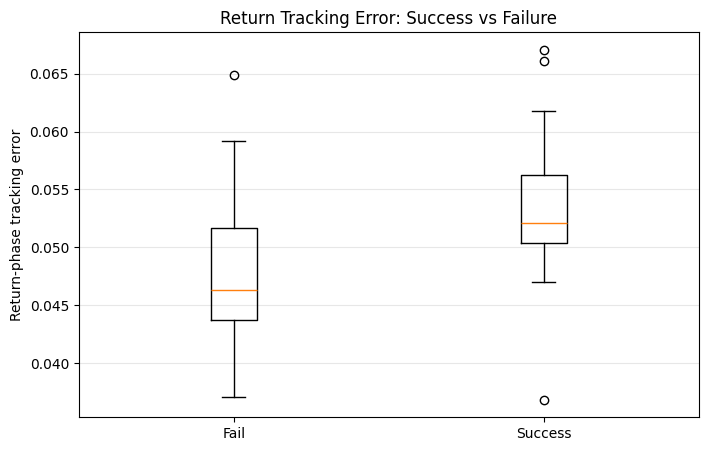

In [56]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

data = [
    test_df.loc[test_df["label"] == 0, "return_track_err"],
    test_df.loc[test_df["label"] == 1, "return_track_err"]
]

plt.boxplot(data, tick_labels=["Fail", "Success"])

plt.ylabel("Return-phase tracking error")
plt.title("Return Tracking Error: Success vs Failure")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [57]:
##SMD to measure how strongly return error separates the two groups
fail = test_df[test_df["label"] == 0]["return_track_err"]
success = test_df[test_df["label"] == 1]["return_track_err"]

pooled_std = (
    ((len(fail)-1)*fail.std()**2 +
     (len(success)-1)*success.std()**2)
    / (len(fail)+len(success)-2)
) ** 0.5

smd = (success.mean() - fail.mean()) / pooled_std

print("SMD:", round(smd, 4))

SMD: 0.8169


In [58]:
feature_sets = {
    "Baseline": [
        "max_track_err",
        "shoulder_roll_movement"
    ],
    "Return error only": [
        "return_track_err"
    ],
    "Return error + shoulder": [
        "return_track_err",
        "shoulder_roll_movement"
    ]
}

for name, features in feature_sets.items():
    X_test = test_df[features]
    y_test = test_df["label"]

    model_test = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ])

    scores = cross_val_score(
        model_test, X_test, y_test, cv=cv
    )

    print(
        f"{name}: "
        f"{scores.mean():.3f} ± {scores.std():.3f}"
    )

Baseline: 0.700 ± 0.100
Return error only: 0.725 ± 0.050
Return error + shoulder: 0.675 ± 0.061


In [59]:
##calculate return-phase tracking error separately for all seven arm joints
from src.config import ARM_JOINTS, state, action
import numpy as np
import pandas as pd

joint_results = []

for eid, df in episodes.items():

    if eid in holdout_ids:
        continue

    ph = detect_phases(df)

    if ph["release_idx"] is None:
        continue

    start = ph["release_idx"]
    end = len(df)

    for joint in ARM_JOINTS:
        s = df[state([joint])[0]].iloc[start:end]
        a = df[action([joint])[0]].iloc[start:end]

        error = (s - a).abs().mean()

        joint_results.append({
            "episode": eid,
            "label": labels[eid],
            "joint": joint,
            "return_error": error
        })

joint_df = pd.DataFrame(joint_results)

print(
    joint_df.groupby(["joint", "label"])["return_error"]
    .mean()
    .unstack()
    .rename(columns={0: "Fail", 1: "Success"})
    .round(4)
)

label     Fail  Success
joint                  
l_el_p  0.0316   0.0331
l_sh_p  0.0779   0.0809
l_sh_r  0.0964   0.1083
l_sh_y  0.0203   0.0210
l_wr_p  0.0284   0.0324
l_wr_r  0.0330   0.0413
l_wr_y  0.0490   0.0580


In [60]:
##compare it against the existing all-seven-joint return_track_err
selected_joints = ["l_sh_r", "l_wr_y", "l_wr_r"]

joint_features = joint_df[
    joint_df["joint"].isin(selected_joints)
]

return_selected = (
    joint_features.groupby(["episode", "label"])["return_error"]
    .mean()
    .reset_index(name="return_error_3j")
)

test_df = test_df.merge(
    return_selected[["episode", "return_error_3j"]],
    on="episode",
    how="left"
)

feature_sets = {
    "All 7 joints": ["return_track_err"],
    "Top 3 joints": ["return_error_3j"]
}

for name, features in feature_sets.items():
    X_test = test_df[features]
    y_test = test_df["label"]

    model_test = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ])

    scores = cross_val_score(
        model_test, X_test, y_test, cv=cv
    )

    print(f"{name}: {scores.mean():.3f} ± {scores.std():.3f}")

All 7 joints: 0.725 ± 0.050
Top 3 joints: 0.725 ± 0.146


In [61]:
##Check return-phase movement
from src.config import ARM_JOINTS, state
import numpy as np
import pandas as pd

movement_results = []

for eid, df in episodes.items():

    if eid in holdout_ids:
        continue

    ph = detect_phases(df)

    if ph["release_idx"] is None:
        continue

    start = ph["release_idx"]
    end = len(df)

    for joint in ARM_JOINTS:
        movement = (
            df[state([joint])[0]]
            .iloc[start:end]
            .diff()
            .abs()
            .sum()
        )

        movement_results.append({
            "episode": eid,
            "label": labels[eid],
            "joint": joint,
            "return_movement": movement
        })

movement_df = pd.DataFrame(movement_results)

print(
    movement_df.groupby("label")["return_movement"]
    .agg(["count", "mean", "std", "median"])
    .round(4)
)

       count    mean     std  median
label                               
0        119  0.3407  0.1144  0.3277
1        161  0.3409  0.1283  0.3244


In [68]:
import importlib
import src.features as f

importlib.reload(f)

print("Total features:", len(f.FEATURE_FUNCTIONS))

for func in f.FEATURE_FUNCTIONS:
    print(func.__name__)

Total features: 14
duration
reach_time
carry_time
return_time
reach_ratio
mean_speed
max_speed
carry_speed
path_length
track_err
max_track_err
n_grasps
shoulder_roll_movement
return_track_err


In [69]:
result = f.extract_features(episodes["000002"])

print("Return tracking error:", result["return_track_err"])

Return tracking error: 0.04972159069548106


In [70]:
import pandas as pd
import numpy as np

df = pd.read_csv("results/features.csv")

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isna().sum())

print("\nInfinite values:")
print(np.isinf(df.select_dtypes(include="number")).sum())

print("\nLabel distribution:")
print(df["label"].value_counts())

print("\nFirst 5 rows:")
display(df.head())

Shape: (48, 16)

Columns:
['episode', 'duration', 'reach_time', 'carry_time', 'return_time', 'reach_ratio', 'mean_speed', 'max_speed', 'carry_speed', 'path_length', 'track_err', 'max_track_err', 'n_grasps', 'shoulder_roll_movement', 'return_track_err', 'label']

Missing values:
episode                   0
duration                  0
reach_time                0
carry_time                0
return_time               0
reach_ratio               0
mean_speed                0
max_speed                 0
carry_speed               0
path_length               0
track_err                 0
max_track_err             0
n_grasps                  0
shoulder_roll_movement    0
return_track_err          0
label                     0
dtype: int64

Infinite values:
episode                   0
duration                  0
reach_time                0
carry_time                0
return_time               0
reach_ratio               0
mean_speed                0
max_speed                 0
carry_speed       

,episode,duration,reach_time,carry_time,return_time,reach_ratio,mean_speed,max_speed,carry_speed,path_length,track_err,max_track_err,n_grasps,shoulder_roll_movement,return_track_err,label
0,2,17.166667,9.700000,4.200000,3.233333,0.565049,0.703798,2.024135,0.793892,12.081872,0.031510,0.207053,1,0.379277,0.049722,1
1,9,12.933333,6.533333,3.700000,2.666667,0.505155,0.714439,2.165070,0.810930,9.240077,0.032405,0.212457,1,0.354637,0.052224,1
2,14,9.933333,4.433333,3.333333,2.133333,0.446309,0.821931,2.702206,0.982694,8.164517,0.038020,0.228291,1,0.368060,0.052699,1
3,16,12.533333,5.433333,4.800000,2.266667,0.433511,0.729539,3.913087,0.798794,9.143557,0.034607,0.236676,1,0.544419,0.054372,1
4,17,12.066667,4.500000,5.233333,2.300000,0.372928,0.761166,2.978321,0.720991,9.184733,0.037106,0.276945,1,0.542694,0.051727,1


In [71]:
##verify that there are no infinite values
print(
    "Total infinite values:",
    np.isinf(df.select_dtypes(include="number")).sum().sum()
)

print("\nDuplicate episodes:", df["episode"].duplicated().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nLabel counts:")
print(df["label"].value_counts().sort_index())

Total infinite values: 0

Duplicate episodes: 0

Duplicate rows: 0

Label counts:
label
0    21
1    27
Name: count, dtype: int64


In [72]:
from src.load import load_folder
from src.sequences import to_fixed_length, build_sequences
from src.config import SEQ_LEN

episodes, labels = load_folder("data/raw")

# Test one episode
eid = list(episodes)[0]
sequence = to_fixed_length(episodes[eid])

print("Single episode:", sequence.shape)

# Test all episodes
X, ids = build_sequences(episodes)

print("All episodes:", X.shape)
print("Number of IDs:", len(ids))
print("Expected sequence length:", SEQ_LEN)
print("Contains NaN:", __import__("numpy").isnan(X).any())

Single episode: (300, 13)
All episodes: (48, 300, 13)
Number of IDs: 48
Expected sequence length: 300
Contains NaN: False
